# 05. Adsorbates

- Teaches how to put an adsorbate on a surface: build it, place it on a site, move it, turn it, and keep the frozen layers of the slab underneath
- An adsorbate is an atom or a molecule that sits on a surface without being part of it; this course uses `O`, `OH` and `OOH`, the intermediates of the oxygen reactions
- The surface underneath is the Pt(1 1 1) slab of module 04, and the canon items that built it (`S2`, `S5`, `S6`, `S8`) still hold here
- Before you start: modules 00 to 04 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
- After this you can place any of the three adsorbates on any of the four sites of a close-packed metal surface, check the structure you built, let a tool enumerate the sites for you, and write the files the calculation modules start from
- Two canon items decide how an adsorbate is placed, and both are open: they are decided per project by your supervisor and written in the project's `CANON.md`
    - `A1`: adsorption-site selection, meaning which sites of the surface are studied at all, and how that list is arrived at
    - `A2`: binding mode and orientation, meaning which atom or atoms of the adsorbate bind to the surface, and how the remaining orientations are sampled
- The numbers used below are teaching values, chosen so that this notebook runs on a laptop in under a minute
    - They are not any project's answer to either item

## 0. The setup cell

- Run this cell first, every time you open the notebook
- This module builds every structure it needs, so it reads no file from `structures/`
    - The clean slab comes from `pt111_slab` in `scripts/onboarding_structures.py`, which is module 04's section on freezing the bottom in one line
- `sys.path` is the list of folders Python searches when it imports something
    - `sys.path.insert(0, ...)` puts the repository's `scripts` folder at the front of that list, and without it `from onboarding_structures import ...` fails, because `scripts` is not next to this notebook
    - `Path("../../scripts").resolve()` turns the relative path into a full path, and `str(...)` turns that path into text, which is what `sys.path` holds
    - The cell prints the path as it is written, `../../scripts`; the full path it resolves to depends on where you keep this repository, so it is different on every computer
    - `sys` and `pathlib` come with Python
- `numpy` is imported under the short name `np` and `pandas` under `pd`, as in modules 01 to 04
    - NumPy holds the positions and the distances of this notebook; pandas prints its tables
- `WORK` is the folder this notebook writes its own files into
    - `WORK.mkdir(exist_ok=True)` creates the folder, and does nothing if it is already there
    - The folder sits inside this module folder and is not saved to the repository
- Two builders come out of the helper, and every section below uses one of them
    - `pt111_slab()` builds the clean three-layer Pt(1 1 1) slab of module 04, 27 atoms, 10 Å of vacuum, bottom layer fixed
    - `pt111_with_adsorbate(species, site)` builds the same slab with an adsorbate already on it, and the section on saving the structures shows what it does

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../../scripts").resolve()))
from onboarding_structures import pt111_slab, pt111_with_adsorbate

WORK = Path("work")
WORK.mkdir(exist_ok=True)

print("Folder this notebook writes into")
print(WORK)
print("Folder the structures helper was imported from")
print(Path("../../scripts"))

clean_slab = pt111_slab()

print()
print("Atoms in the clean Pt(1 1 1) slab")
print(len(clean_slab))
print("Fixed atoms in it")
print(len(clean_slab.constraints[0].get_indices()))

Folder this notebook writes into
work
Folder the structures helper was imported from
../../scripts

Atoms in the clean Pt(1 1 1) slab
27
Fixed atoms in it
9


## 1. Build the adsorbates

- The three adsorbates of this course are built by hand here, so that every number in them is visible before any of them touches a surface
- The anchor atom is the atom of the adsorbate that binds to the surface
    - It is atom 0 in all three below, which for `OH` and `OOH` is the oxygen written first in the formula
    - Which atom is the anchor is part of canon `A2`: a molecule that can bind through more than one of its atoms has more than one sensible answer, and the project decides
- Each one is an `Atoms` object, built from a formula and one position per atom in Å, as in module 02
    - `Atoms("O")` is a single oxygen atom at the origin, so it has no internal geometry to get wrong
    - `Atoms("OH", positions=[[0, 0, 0], [0, 0, 0.97]])` puts the H 0.97 Å straight above the O
    - `Atoms("OOH", positions=[[0, 0, 0], [0.9, 0, 1.1], [1.75, 0, 0.63]])` gives an O to O distance of 1.42 Å, with the H on the outer O and the group bent
    - The formula fixes the order, so in `OOH` atom 0 is the anchor O, atom 1 the outer O and atom 2 the H
- These are starting geometries, not results
    - 0.97 Å is about the O to H distance of a free hydroxyl group and 1.42 Å about the O to O distance of hydrogen peroxide, which is close enough to start a relaxation from
    - The relaxation of module 07 changes them, and the numbers that go into a result are the relaxed ones
- The same three objects are in `scripts/onboarding_structures.py`, with the same positions, so a later notebook does not build them again
- `atoms.get_distance(i, j)` is the distance between two atoms in Å, as in module 02
- `atoms.get_angle(i, j, k)` is the angle at atom `j` between the bond to `i` and the bond to `k`, in degrees
- `np.round(values, 3)` rounds a whole array to three decimals, for printing only, as in modules 01, 02 and 04

In [2]:
from ase import Atoms

o_ads = Atoms("O")
oh_ads = Atoms("OH", positions=[[0.0, 0.0, 0.0], [0.0, 0.0, 0.97]])
ooh_ads = Atoms("OOH", positions=[[0.0, 0.0, 0.0], [0.9, 0.0, 1.1], [1.75, 0.0, 0.63]])

print("Atoms in the O adsorbate")
print(len(o_ads))
print("Position of the O adsorbate (Å)")
print(np.round(o_ads.positions, 3))

print()
print("Symbols of the OH group, in the order they are stored")
print(oh_ads.get_chemical_symbols())
print("Positions of the OH group (Å)")
print(np.round(oh_ads.positions, 3))
print("O to H distance in OH (Å)")
print(round(float(oh_ads.get_distance(0, 1)), 3))

print()
print("Symbols of the OOH group, in the order they are stored")
print(ooh_ads.get_chemical_symbols())
print("Positions of the OOH group (Å)")
print(np.round(ooh_ads.positions, 3))
print("Anchor O to outer O distance in OOH (Å)")
print(round(float(ooh_ads.get_distance(0, 1)), 3))
print("Outer O to H distance in OOH (Å)")
print(round(float(ooh_ads.get_distance(1, 2)), 3))
print("Angle at the outer O, anchor O to outer O to H (°)")
print(round(float(ooh_ads.get_angle(0, 1, 2)), 2))

Atoms in the O adsorbate
1
Position of the O adsorbate (Å)
[[0. 0. 0.]]

Symbols of the OH group, in the order they are stored
['O', 'H']
Positions of the OH group (Å)
[[0.   0.   0.  ]
 [0.   0.   0.97]]
O to H distance in OH (Å)
0.97

Symbols of the OOH group, in the order they are stored
['O', 'O', 'H']
Positions of the OOH group (Å)
[[0.   0.   0.  ]
 [0.9  0.   1.1 ]
 [1.75 0.   0.63]]
Anchor O to outer O distance in OOH (Å)
1.421
Outer O to H distance in OOH (Å)
0.971
Angle at the outer O, anchor O to outer O to H (°)
100.35


## 2. The four sites on fcc(1 1 1)

- An adsorption site is a place on the surface where an adsorbate sits, and on a close-packed metal face there are four of them, named after the atoms underneath
    - `ontop`: directly above one atom of the top layer
    - `bridge`: halfway between two neighbouring atoms of the top layer
    - `fcc`: in the three-fold hollow between three atoms of the top layer, with no atom of the second layer directly below it
    - `hcp`: in the other three-fold hollow, with an atom of the second layer directly below it
    - The two hollows look identical from above and are different structures, because what sits in the second layer is different; module 07 computes how much they differ in energy for this model
- Which of the four are studied at all is canon `A1`, decided per project and written in the project's `CANON.md`
    - This notebook builds all four, which is a teaching choice and not a recommendation
- `add_adsorbate(slab, adsorbate, height=h, position="fcc")` puts the adsorbate on the named site
    - It knows where the four sites are because `ase.build.fcc111` wrote their coordinates into `slab.info` when it built the slab; the names therefore work for a slab from that builder and not for an arbitrary structure
    - `height` is the distance in Å along z from the top layer of the slab to the anchor atom
    - `mol_index=0` chooses which atom of the adsorbate is put at that height; 0 is the default, and it is the anchor atom of the section on building the adsorbates
    - `position` also takes a pair of numbers, `position=(x, y)` in Å, which is the way to reach a site that has no name
- `add_adsorbate` changes both objects it is given instead of returning a new one
    - The slab grows by the atoms of the adsorbate, so calling it twice on the same slab gives a slab with two adsorbates on it
    - The adsorbate object itself is moved onto the surface, so after the call the template is no longer the free molecule at the origin
    - The anchor still lands in the right place the next time it is used, because the placement is absolute, but anything else done to that template first, such as a rotation without a `center` or a printed bond geometry, then starts from the wrong coordinates
    - The way out is a copy, every time: this notebook builds a fresh `pt111_slab()` for each site and passes `Atoms("O")` built on the spot, and `scripts/onboarding_structures.py` copies its template before every placement
    - `View > Repeat ...` in `ase gui` changed the structure in memory in the same way in module 02; a tool that changes what it is handed is common, and a copy is always the answer
- The heights used here are the ones in `scripts/onboarding_structures.py`, one per species and per site
    - For O they are 1.85 Å ontop, 1.45 Å bridge and 1.30 Å in both hollows
    - They are chosen so that the O to Pt distance starts between about 1.9 and 2.1 Å, which is near where a relaxed O sits on Pt
    - A hollow takes a lower height than an ontop site, because an adsorbate in a hollow already gains distance from each of the three Pt atoms sideways
    - They are starting guesses; the relaxation of module 07 decides the height, and a height is never reported from this table
- Coverage is how many adsorbates sit on how much surface, usually counted per atom of the top layer
    - One adsorbate on this 3 by 3 cell, whose top layer holds 9 Pt atoms, is a coverage of 1/9, written 0.11 monolayer
    - Canon `S6` is what makes that number meaningful: the cell is wide enough, 8.316 Å, that the adsorbate is far from its own periodic copy
    - `slab.get_tags()` gives the layer index of each slab atom, 1 for the top layer, as in module 04, so `(tags == 1).sum()` counts the atoms of the top layer and `int(...)` makes it a plain number
- `slab.get_distances(i, indices, mic=True)` gives the distances in Å from atom `i` to every atom in the list
    - `mic=True` is the minimum image convention of module 02, and it is needed here because a site near the edge of the cell has its nearest Pt in the next copy
    - `distances.min()` is the shortest of them, and `float(...)` turns it into a plain number for printing
    - `(distances < distances.min() + 0.1).sum()` counts how many Pt atoms sit within 0.1 Å of that shortest distance, which is how many atoms the adsorbate is really sharing its site with
- `[i for i, symbol in enumerate(symbols) if symbol == "Pt"]` builds the list of the indices of every Pt atom in one line, which is the short spelling of the loop module 04 used to collect its bottom layer
- `pd.DataFrame(rows).to_string(index=False)` prints a list of dictionaries as an aligned table without row numbers, as in modules 01 to 04
- `plot_atoms(atoms, ax, radii=0.5)` draws the structure into one panel, as in modules 02 and 04; with no `rotation` argument it draws the top view, looking down the z axis
- `plt.subplots(2, 2, figsize=(6, 6), sharex=True, sharey=True)` makes a 2 by 2 grid of panels that share one pair of axes, as the two-panel figures of module 04 did
    - The four panels come back as a 2 by 2 NumPy array, and `axes.ravel()` flattens it into a list of four, so that one loop can walk through them
    - `zip(axes.ravel(), SITES)` walks the panels and the site names together, one pair per turn of the loop, the way `enumerate` of module 01 walks a list together with its positions
- In the figure:
    - The same slab four times, seen from above, with the single red O atom on a different site in each panel
    - The panels share their axes, so the four slabs are drawn at the same scale and only the O moves
    - `ontop` sits on a Pt atom, `bridge` between two, and the two hollows in the middle of a triangle of three; the two hollows cannot be told apart from above, which is the point of the picture
    - The `ontop` site of this slab is at the corner of the cell, so its O is drawn at the edge of the panel; it is the same site as the one above any other Pt atom of the top layer, because the cell repeats
- In the table:
    - The nearest Pt is 1.850 Å from the O ontop, 2.006 Å at the bridge and 2.062 Å in both hollows, so all four starting guesses land in the intended range
    - The count of Pt atoms at that distance is 1, 2, 3 and 3, which is the site name checked against the geometry rather than trusted
    - The two hollows give identical distances, because they differ only in the second layer

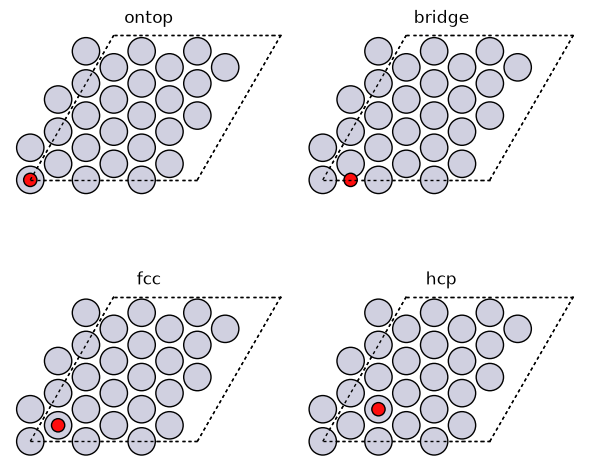

Atoms in the top layer of the slab
9
Shortest in-plane cell vector (Å)
8.316

One O atom on each of the four sites of Pt(1 1 1)
  site  height given (Å)  O to nearest Pt (Å)  Pt atoms within 0.1 Å of that  atoms in the structure
 ontop              1.85                1.850                              1                      28
bridge              1.45                2.006                              2                      28
   fcc              1.30                2.062                              3                      28
   hcp              1.30                2.062                              3                      28


In [3]:
import matplotlib.pyplot as plt
from ase.build import add_adsorbate
from ase.visualize.plot import plot_atoms

SITES = ("ontop", "bridge", "fcc", "hcp")
HEIGHT_O = {"ontop": 1.85, "bridge": 1.45, "fcc": 1.30, "hcp": 1.30}

slabs = {}
rows = []

fig, axes = plt.subplots(2, 2, figsize=(6, 6), sharex=True, sharey=True)
for ax, site in zip(axes.ravel(), SITES):
    slab = pt111_slab()
    add_adsorbate(slab, Atoms("O"), height=HEIGHT_O[site], position=site)
    slabs[site] = slab

    i_o = len(slab) - 1
    pt_indices = [i for i, symbol in enumerate(slab.get_chemical_symbols()) if symbol == "Pt"]
    distances = slab.get_distances(i_o, pt_indices, mic=True)
    rows.append({"site": site,
                 "height given (Å)": HEIGHT_O[site],
                 "O to nearest Pt (Å)": round(float(distances.min()), 3),
                 "Pt atoms within 0.1 Å of that": int((distances < distances.min() + 0.1).sum()),
                 "atoms in the structure": len(slab)})

    plot_atoms(slab, ax, radii=0.5)
    ax.set_title(site, fontsize=12)

fig.tight_layout()
plt.show()

print("Atoms in the top layer of the slab")
print(int((clean_slab.get_tags() == 1).sum()))
print("Shortest in-plane cell vector (Å)")
print(round(float(min(clean_slab.cell.lengths()[:2])), 3))

print()
print("One O atom on each of the four sites of Pt(1 1 1)")
print(pd.DataFrame(rows).to_string(index=False))

## 3. Move an adsorbate

- Placing on a named site is the quick way; moving the adsorbate by hand is what you do when the site you want has no name, or when a relaxation ended somewhere unhelpful and you want to start it again from a different guess
- The structure moved here is the `fcc` one of the section on the four sites, copied first
    - `atoms.copy()` makes a separate structure, as in module 02, so the structure that section built is left as it was
- Two moves, and both act on the row of `positions` that belongs to the adsorbate
    - `atoms.positions[i, 0] += 0.3` adds 0.3 Å to the x of atom `i` and leaves y and z alone
    - `atoms.positions[i, 2] = top_z + 1.8` sets the z of atom `i` so that it sits 1.8 Å above the top layer, which is a height and not a shift
- The height has to be measured against the top layer, never against the bottom of the cell
    - `atoms.get_tags()` is the layer index of the section on the four sites; the adsorbate carries the tag 0, because `add_adsorbate` writes no tag on what it adds
    - `positions[tags == 1, 2].max()` is therefore the height of the top layer of Pt, and every height in this notebook is counted from it
- The same measurement is made three times, so it is written once as a function, as module 04 wrote its layer counter
    - `nearest_metal(structure, index, metal_indices)` gives back two numbers: the shortest distance to a metal atom, and how many metal atoms sit within 0.1 Å of it
    - `shortest, sharing = nearest_metal(...)` puts those two numbers into two names in one line
    - Everything it needs is passed in, so it can be read on its own and used on another structure
- What the printed distances say about the two moves
    - As placed, three Pt atoms sit at 2.062 Å: the O is in the three-fold hollow and shares it with all three
    - After 0.3 Å along x the shortest distance falls to 1.873 Å and only one Pt is within 0.1 Å of it: a shift much smaller than a bond length has taken the O out of the hollow and pushed it towards one atom
    - After raising it to 1.8 Å above the top layer the shortest distance grows to 2.249 Å, which is longer than any of the four starting guesses and would be a poor place to begin a relaxation from
    - A small move changes the site and the chemistry; this is why a structure is measured after it is built and not assumed from the line that built it

In [4]:
moved = slabs["fcc"].copy()
tags = moved.get_tags()
top_z = float(moved.positions[tags == 1, 2].max())

i_o = len(moved) - 1
pt_indices = [i for i, symbol in enumerate(moved.get_chemical_symbols()) if symbol == "Pt"]


def nearest_metal(structure, index, metal_indices):
    """Shortest distance from one atom to the metal, and how many metal atoms share it."""
    d = structure.get_distances(index, metal_indices, mic=True)
    return round(float(d.min()), 3), int((d < d.min() + 0.1).sum())


print("Height of the top layer of Pt above the bottom of the cell (Å)")
print(round(top_z, 3))

shortest, sharing = nearest_metal(moved, i_o, pt_indices)
print()
print("Position of the O as placed on the fcc site (Å)")
print(np.round(moved.positions[i_o], 3))
print("Its height above the top layer (Å)")
print(round(float(moved.positions[i_o, 2] - top_z), 3))
print("O to nearest Pt as placed (Å)")
print(shortest)
print("Pt atoms within 0.1 Å of that distance")
print(sharing)

moved.positions[i_o, 0] += 0.3
shortest, sharing = nearest_metal(moved, i_o, pt_indices)
print()
print("Position of the O after moving it 0.3 Å along x (Å)")
print(np.round(moved.positions[i_o], 3))
print("O to nearest Pt after that move (Å)")
print(shortest)
print("Pt atoms within 0.1 Å of that distance")
print(sharing)

moved.positions[i_o, 2] = top_z + 1.8
shortest, sharing = nearest_metal(moved, i_o, pt_indices)
print()
print("Position of the O after setting its height to 1.8 Å above the top layer (Å)")
print(np.round(moved.positions[i_o], 3))
print("Its height above the top layer (Å)")
print(round(float(moved.positions[i_o, 2] - top_z), 3))
print("O to nearest Pt after the height change (Å)")
print(shortest)
print("Pt atoms within 0.1 Å of that distance")
print(sharing)

Height of the top layer of Pt above the bottom of the cell (Å)
14.526

Position of the O as placed on the fcc site (Å)
[ 1.386  0.8   15.826]
Its height above the top layer (Å)
1.3
O to nearest Pt as placed (Å)
2.062
Pt atoms within 0.1 Å of that distance
3

Position of the O after moving it 0.3 Å along x (Å)
[ 1.686  0.8   15.826]
O to nearest Pt after that move (Å)
1.873
Pt atoms within 0.1 Å of that distance
1

Position of the O after setting its height to 1.8 Å above the top layer (Å)
[ 1.686  0.8   16.326]
Its height above the top layer (Å)
1.8
O to nearest Pt after the height change (Å)
2.249
Pt atoms within 0.1 Å of that distance
1


## 4. Rotate an adsorbate about its anchor

- Orientation is how the adsorbate is turned about its anchor atom while the anchor stays on the same site
    - A single O atom has no orientation; `OH` and `OOH` have one, because they have atoms that are not the anchor
    - Choosing orientations is canon `A2`, and it is a project decision: a relaxation moves the atoms but it does not turn a group over, so an orientation that is never built is never tested
- `OOH` is placed here on the `ontop` site at a height of 2.00 Å, the value the helper uses for `OOH` on that site
    - `offset=(1, 1)` moves the placement one surface cell along each of the two in-plane vectors, which puts the group near the middle of the picture instead of at the corner of the cell
    - It is the same site and the same structure: the two places are copies of each other one cell apart, so every distance below is the same either way
- Turning a group inside a larger structure is done in three steps, as module 02 showed
    1. Take the group out: `fragment = structure[[i, j, k]]` builds a small `Atoms` object from those atom indices
    2. Turn the small object: `fragment.rotate(15, "z", center=fragment[0].position)` turns it by 15° about the z axis through its own atom 0
    3. Write it back: `structure.positions[[i, j, k]] = fragment.positions`
- `center=` is the point that stays where it is, and here it is the anchor O
    - Without it the rotation turns about the origin of the coordinates, which moves the whole group off its site
    - Rotating the whole structure instead of the fragment would turn the slab as well, and the slab no longer matches its own cell when that happens
- The adsorbate indices are known because the adsorbate was appended after the slab atoms
    - `len(pt111_slab())` is 27, so the anchor O is atom 27, the outer O is atom 28 and the H is atom 29
    - The section on keeping the frozen layers comes back to why appending at the end matters
- Two small functions do the repeated work, as the section on moving an adsorbate wrote its measurement once
    - `rotated(angle)` gives back a copy of the structure with the group turned by that angle about its anchor, which is the three steps above under one name, and both the figure and the check below use it
    - `distance_list(structure)` gives back one sorted array holding every distance from the three adsorbate atoms to every Pt atom, which is what the check below compares between two orientations
- Which angles are worth building is decided by the symmetry of the site, and that is what this section is really about
    - The `ontop` site of this slab has a three-fold axis: turning the surface by 120° or by 240° maps it onto itself
    - The site also has three mirror planes, and they run along the directions halfway between two neighbouring Pt atoms, at 30°, at 90° and at 150° from the x axis
    - The axis and the mirror planes together make 0°, 60°, 120°, 180°, 240° and 300° one single structure: each of them points the arm of the group at a nearest-neighbour Pt atom, and a calculation returns the same energy for all six, apart from the numerical noise of the calculation
    - The six nearest Pt atoms of the top layer lie in exactly those six directions, 2.772 Å from the Pt atom the anchor sits on, measured in the surface plane
    - That spacing is the nearest-neighbour distance of the 1 by 1 surface cell (2.772 Å), and not a dimension of the 3 by 3 supercell (8.316 Å), which is the number the section on the four sites printed
    - The cell measures it as the shortest Pt to Pt distance in the top layer, which is the same distance, because the anchor sits directly above one of those Pt atoms
    - A scan over 0°, 60° and 120° would therefore have built three copies of one structure and spent three relaxations to get one answer; avoiding that is the point of the check below
- The angles used below are 0°, 15° and 30°, and no symmetry operation of the site maps any one of the three onto another
    - Symmetry gives no more than that: with no operation of the site relating the three, nothing requires their energies to be equal, so each of the three has to be calculated and none of them can be inferred from another
    - The 0°, 60° and 120° case is the opposite: symmetry does require those three energies to be equal, so one calculation answers for all three
    - Inequivalent is not the same as different: two orientations that no symmetry operation relates can still come out at the same energy, and only a calculation says whether they do
    - The check below turns the group all the way round in steps of 15° and groups the angles that give the same structure, so the three angles of the figure can be seen to be in three different groups
- Covering every distinct orientation takes a 60° range that runs from one mirror direction to the next, for example 30° to 90°
    - 0° to 30° is not enough: 75° is a fourth structure and 90° a fifth, and no symmetry operation of the site brings either of them inside that range
    - Three orientations are enough for this section, which teaches how to turn a group and how to tell two orientations apart, not how to run a complete scan
- How many orientations to sample and which ones is canon `A2`, a per-project decision, and on an oxide the answer is a longer list
    - An oxide site has lower symmetry than this one, so fewer orientations are related to each other by symmetry and more of them have to be built and tried
    - The neighbourhood of an oxide site is also not the same in every direction, with metal cations, oxygen anions and vacancies at different places, so two orientations can differ by enough to change the answer
    - A single guessed orientation is a result about that guess
- `np.sort(values)` puts the numbers of an array in increasing order
- `np.concatenate([first, second, third])` joins several arrays end to end into one longer array
- `np.allclose(a, b, rtol=0.0, atol=1e-6)` answers whether two arrays of the same shape agree everywhere to within 1e-6, here 1e-6 Å
- `range(0, 360, 15)` is every whole number from 0 to 345 in steps of 15, which is the list of angles the check turns the group by
- `enumerate(groups, start=1)` walks a list together with a counter that starts at 1 instead of 0, as in module 01
- `", ".join(str(a) for a in angles)` turns a list of numbers into one line of text with commas between them, so that a whole group of angles fits in one table cell
- In the figure:
    - The same structure three times from above, turned by 0°, 15° and 30° about the anchor O
    - The anchor O stays on its Pt atom in all three panels, and what moves is the arm: the red outer O and the small white H swing around it
    - One step from panel to panel is a turn of 15°, so the change is small; the table is where to read what actually moved
- In the table of the three orientations:
    - The x and y of the outer O and of the H change with every rotation, and their heights do not, because the turn is about the z axis
    - The anchor O to nearest Pt distance is 2.0 Å in all three, so the anchor never left its site
    - The O to O distance is 1.421 Å in all three: a rotation moves atoms and changes no distance inside the group
- In the table of distinct structures:
    - Two orientations are counted as the same structure when the sorted list of every distance from the three adsorbate atoms to every Pt atom is identical
    - A symmetry operation of the site moves atoms around but cannot change that list, so a list that differs proves that two orientations are different structures
    - Five structures come out of the 24 angles sampled, and the five groups are what the three-fold axis and the mirror planes of the site predict, which is the check that the grouping is symmetry and not a coincidence
    - 0°, 15° and 30° sit in three different groups, and 75° and 90° are the two groups that a scan from 0° to 30° would never reach

Symbols of the three atoms that were appended to the slab
['O', 'O', 'H']
Position of the anchor O, the point every rotation turns about (Å)
[ 4.158  2.4   16.526]
Position of the outer O before any rotation (Å)
[ 5.058  2.4   17.626]
Position of the H before any rotation (Å)
[ 5.908  2.4   17.156]

Nearest Pt to Pt distance in the top layer (Å)
2.772


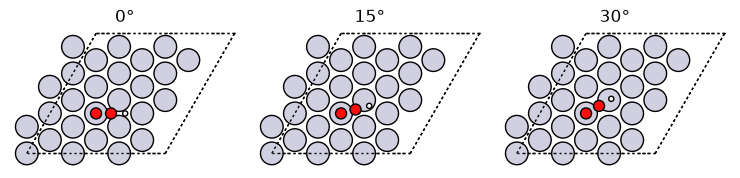


Three orientations of OOH on the ontop site, turned about the anchor O
 rotation (°)  outer O x (Å)  outer O y (Å)  H x (Å)  H y (Å)  anchor O to nearest Pt (Å)  O to O (Å)
            0          5.058          2.400    5.908    2.400                         2.0       1.421
           15          5.027          2.633    5.848    2.853                         2.0       1.421
           30          4.937          2.850    5.673    3.275                         2.0       1.421

Distinct structures among the rotations 0° to 345° in steps of 15°
 structure  rotations that give it (°)
         1   0, 60, 120, 180, 240, 300
         2  15, 45, 135, 165, 255, 285
         3                30, 150, 270
         4 75, 105, 195, 225, 315, 345
         5                90, 210, 330


In [5]:
base = pt111_slab()
n_slab = len(base)
add_adsorbate(base, ooh_ads.copy(), height=2.00, position="ontop", offset=(1, 1), mol_index=0)

fragment_indices = [n_slab, n_slab + 1, n_slab + 2]
pt_indices = [i for i, symbol in enumerate(base.get_chemical_symbols()) if symbol == "Pt"]
top_pt_indices = [i for i in pt_indices if base.get_tags()[i] == 1]


def rotated(angle):
    """A copy of the structure with the adsorbate turned by angle degrees about its anchor."""
    turned = base.copy()
    fragment = turned[fragment_indices]
    fragment.rotate(angle, "z", center=fragment[0].position)
    turned.positions[fragment_indices] = fragment.positions
    return turned


def distance_list(structure):
    """Every distance from the three adsorbate atoms to every Pt atom, in one sorted array."""
    per_atom = [structure.get_distances(i, pt_indices, mic=True) for i in fragment_indices]
    return np.sort(np.concatenate(per_atom))


print("Symbols of the three atoms that were appended to the slab")
print([base[i].symbol for i in fragment_indices])
print("Position of the anchor O, the point every rotation turns about (Å)")
print(np.round(base.positions[fragment_indices[0]], 3))
print("Position of the outer O before any rotation (Å)")
print(np.round(base.positions[fragment_indices[1]], 3))
print("Position of the H before any rotation (Å)")
print(np.round(base.positions[fragment_indices[2]], 3))

print()
print("Nearest Pt to Pt distance in the top layer (Å)")
print(round(float(base.get_distances(top_pt_indices[0], top_pt_indices[1:], mic=True).min()), 3))

rows = []

fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.8), sharex=True, sharey=True)
for ax, angle in zip(axes, (0, 15, 30)):
    turned = rotated(angle)

    anchor_distances = turned.get_distances(fragment_indices[0], pt_indices, mic=True)
    rows.append({"rotation (°)": angle,
                 "outer O x (Å)": round(float(turned.positions[fragment_indices[1], 0]), 3),
                 "outer O y (Å)": round(float(turned.positions[fragment_indices[1], 1]), 3),
                 "H x (Å)": round(float(turned.positions[fragment_indices[2], 0]), 3),
                 "H y (Å)": round(float(turned.positions[fragment_indices[2], 1]), 3),
                 "anchor O to nearest Pt (Å)": round(float(anchor_distances.min()), 3),
                 "O to O (Å)": round(float(turned.get_distance(fragment_indices[0],
                                                              fragment_indices[1])), 3)})

    plot_atoms(turned, ax, radii=0.5)
    ax.set_title(str(angle) + "°", fontsize=12)

fig.tight_layout()
plt.show()

print()
print("Three orientations of OOH on the ontop site, turned about the anchor O")
print(pd.DataFrame(rows).to_string(index=False))

groups = []
for angle in range(0, 360, 15):
    current = distance_list(rotated(angle))
    matched = False
    for group in groups:
        if np.allclose(current, group["distances"], rtol=0.0, atol=1e-6):
            group["angles"].append(angle)
            matched = True
            break
    if not matched:
        groups.append({"distances": current, "angles": [angle]})

rows = []
for number, group in enumerate(groups, start=1):
    rows.append({"structure": number,
                 "rotations that give it (°)": ", ".join(str(a) for a in group["angles"])})

print()
print("Distinct structures among the rotations 0° to 345° in steps of 15°")
print(pd.DataFrame(rows).to_string(index=False))

## 5. Enumerate sites automatically

- Naming the four sites by hand works on a close-packed face; a tool that finds them is what you reach for on a surface whose sites you do not already know
- `AdsorbateSiteFinder` is pymatgen's tool for it, and it works on a pymatgen structure, so the ASE slab is converted first
    - `AseAtomsAdaptor.get_structure(atoms)` converts an ASE `Atoms` object into a pymatgen `Structure`; module 03 used `get_atoms` to go the other way
    - `AdsorbateSiteFinder(structure)` prepares the finder, and `find_adsorption_sites()` does the work
    - The result is a dictionary with the keys `ontop`, `bridge`, `hollow` and `all`, and each one holds a list of positions in Å
    - The positions are 2.0 Å above the surface, which is the default of the `distance` argument and not a relaxed height; the height still has to be chosen, as the section on the four sites did
- What the counts mean, and what they do not
    - The finder returns one entry per symmetry-distinct site, not one per copy: this cell has 9 ontop sites and the finder lists 1
    - It returns 2 hollow sites, which are the `fcc` and the `hcp` hollow, and it does not say which of them is which
    - The positions it returns need not be the ones ASE used: the `ontop` site and one hollow come out at the same place, the other hollow is the `hcp` site moved by whole cell vectors, and the bridge is a different bond of the same kind
    - Any copy of a site is the same site, whether it is reached by a cell vector or by a symmetry operation of the surface, so the two lists agree as a list of site types and not entry by entry
    - On this surface the finder therefore reproduces the four names of the section on the four sites, and it is that agreement on a surface you already know which makes it worth trusting on one you do not
- Canon `A1` is which sites are studied, and a fixed list of geometric names is only the answer for a flat close-packed face
    - The four names are definitions taken from the geometry of that face: one atom of the top layer below the adsorbate, two of them, or three of them with and without an atom of the second layer underneath
    - On a step, an alloy or an oxide that geometry is not there to be matched: the atoms around a site sit at more than one height, or are of more than one element, so none of the four names says what the adsorbate is bound to
    - The group's method for those surfaces is scan-relax site discovery: a site is defined as a binding-energy minimum, found by scanning the adsorbate over a frozen surface and grouping the relaxed end points by energy, which needs no name for a site at all
    - The tool is `compcatalysis-skills/adsorbate-placement` in the group's skills repository; your supervisor will point you at it when your surface needs it
- `np.array(list_of_positions)` turns a list of positions into one NumPy array, so that `np.round` can round all of them at once
- In the table:
    - One row per site type, with how many distinct sites the finder returned for the clean 3 by 3 slab
    - 1 ontop, 1 bridge and 2 hollow, which is the four sites of this surface with the two hollows not yet told apart

In [6]:
from pymatgen.analysis.adsorption import AdsorbateSiteFinder
from pymatgen.io.ase import AseAtomsAdaptor

structure = AseAtomsAdaptor.get_structure(clean_slab)
finder = AdsorbateSiteFinder(structure)
found = finder.find_adsorption_sites()

rows = []
for kind in ("ontop", "bridge", "hollow"):
    rows.append({"site type": kind, "distinct sites found": len(found[kind])})

print("Sites AdsorbateSiteFinder returned for the clean Pt(1 1 1) slab")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("Entries in the 'all' list, which is the three types together")
print(len(found["all"]))
print("Positions of every site it returned (Å)")
print(np.round(np.array(found["all"]), 3))
print("Height of the top layer of the slab (Å)")
print(round(float(clean_slab.positions[clean_slab.get_tags() == 1, 2].max()), 3))

Sites AdsorbateSiteFinder returned for the clean Pt(1 1 1) slab
site type  distinct sites found
    ontop                     1
   bridge                     1
   hollow                     2

Entries in the 'all' list, which is the three types together
4
Positions of every site it returned (Å)
[[ 0.     0.    16.526]
 [ 2.079  1.2   16.526]
 [ 1.386  0.8   16.526]
 [ 5.544  6.401 16.526]]
Height of the top layer of the slab (Å)
14.526


## 6. Keep the frozen layers

- A frozen layer is a layer at the bottom of the slab whose atoms may not move during a relaxation, and it is what makes the slab a model of a surface instead of a model of a thin film
    - `pt111_slab()` freezes the bottom layer, 9 atoms of the 27, through `FixAtoms` as module 04 did
    - How many layers are frozen is canon `S8`, decided per project
- The constraint is stored as a list of atom indices, so anything that changes the indices can break it silently
    - `atoms.constraints[0].get_indices()` is that list, and its length is the number of fixed atoms
    - `(fixed == i).any()` asks whether the index `i` appears in the list, and `bool(...)` turns the answer into a plain `True` or `False`
- `add_adsorbate` is safe for the constraint, and the reason is worth knowing rather than trusting
    - It appends the adsorbate after the slab atoms, so every atom that was already there keeps the index it had
    - The fixed list therefore still points at the same 9 Pt atoms, and the adsorbate, which is the last atom, is free to move
- What is not safe is anything that reorders atoms
    - `write(..., sort=True)` groups the atoms by species before writing, so in a file holding O and Pt the O comes first and every Pt index shifts, as module 04 showed
    - The flags in the file follow their own atoms, so the file stays correct; it is an index list kept on the side that goes wrong
    - Read the file back and check the fixed atoms by their height or their symbol, never by the index they had before the write
- Check the constraint after every operation that touches the structure, and print the number
    - A relaxation with nothing fixed runs to the end and reports success, so a lost constraint is not an error you will be told about

In [7]:
check = pt111_slab()
fixed_before = check.constraints[0].get_indices()

add_adsorbate(check, Atoms("O"), height=1.30, position="fcc")
fixed_after = check.constraints[0].get_indices()
i_adsorbate = len(check) - 1

print("Fixed atoms in the clean slab")
print(len(fixed_before))
print("Fixed atoms after add_adsorbate")
print(len(fixed_after))
print("Indices of the fixed atoms after add_adsorbate")
print(fixed_after)

print()
print("Atoms in the structure")
print(len(check))
print("Index of the adsorbate atom")
print(i_adsorbate)
print("Is the adsorbate fixed")
print(bool((fixed_after == i_adsorbate).any()))
print("Atoms free to move")
print(len(check) - len(fixed_after))

Fixed atoms in the clean slab
9
Fixed atoms after add_adsorbate
9
Indices of the fixed atoms after add_adsorbate
[0 1 2 3 4 5 6 7 8]

Atoms in the structure
28
Index of the adsorbate atom
27
Is the adsorbate fixed
False
Atoms free to move
19


## 7. Save the structures for module 07

- Five structures are written into `work/`, in the VASP format of module 02
    - `Pt111_O_ontop.vasp`, `Pt111_O_bridge.vasp`, `Pt111_O_fcc.vasp` and `Pt111_O_hcp.vasp`, the four structures of the section on the four sites
    - `Pt111_OH_fcc.vasp`, an OH group in the fcc hollow, built by the helper
    - `write(path, atoms, format="vasp", direct=True, sort=True)` writes them in fractional coordinates with the atoms grouped by species, and carries the fixed atoms into the file as the `F F F` flags
- `pt111_with_adsorbate(species, site)` is this whole notebook in one line
    - `pt111_with_adsorbate("O", "fcc")` builds the clean slab, copies the O template, looks the height up in its own table and places it, which is exactly what the section on the four sites did by hand
    - The cell below compares the two structures atom by atom and prints the largest difference, which is how you check that a helper does what you think it does
    - The calculation modules build their inputs with this one line, so they run without this module's `work/` folder; the files written here are for your own use, to open in `ase gui`, to measure, and to compare with what the group's scripts produce
- The files are read back and measured, because a write is only known to have worked once something has read it
    - `read(path)` gives an `Atoms` object back, as in module 02
    - The atom order in the file is not the atom order in memory: with `sort=True` the O of `Pt111_O_fcc.vasp` is the first atom of the file, and in `Pt111_OH_fcc.vasp` the order is H, then O, then the 27 Pt
    - The O is therefore found by its symbol, `symbols.index("O")`, and never by the index it had before the write
- `np.abs(a - b).max()` is the largest absolute difference between two arrays of the same shape, here two sets of atom positions in Å
- In the table:
    - One row per file, with what ASE reads back out of it
    - 9 fixed atoms in every file, the bottom layer that canon `S8` kept
    - The O to nearest Pt distances match the ones built above, so nothing was lost in the write and the read

In [8]:
from ase.io import read, write

paths = []
for site in SITES:
    path = WORK / ("Pt111_O_" + site + ".vasp")
    write(path, slabs[site], format="vasp", direct=True, sort=True)
    paths.append(path)

helper_fcc = pt111_with_adsorbate("O", "fcc")

print("Largest difference between the hand-built O on fcc and the helper's (Å)")
print(round(float(np.abs(helper_fcc.positions - slabs["fcc"].positions).max()), 6))
print("Same chemical symbols in the same order")
print(helper_fcc.get_chemical_symbols() == slabs["fcc"].get_chemical_symbols())

oh_fcc = pt111_with_adsorbate("OH", "fcc")
oh_path = WORK / "Pt111_OH_fcc.vasp"
write(oh_path, oh_fcc, format="vasp", direct=True, sort=True)
paths.append(oh_path)

rows = []
for path in paths:
    atoms = read(path)
    symbols = atoms.get_chemical_symbols()
    i_o = symbols.index("O")
    pt_indices = [i for i, symbol in enumerate(symbols) if symbol == "Pt"]
    rows.append({"file": path.name,
                 "atoms": len(atoms),
                 "formula": atoms.get_chemical_formula(),
                 "fixed atoms": len(atoms.constraints[0].get_indices()),
                 "index of the O in the file": i_o,
                 "O to nearest Pt (Å)": round(float(atoms.get_distances(i_o, pt_indices,
                                                                       mic=True).min()), 3)})

print()
print("Files written into the work folder, then read back")
print(pd.DataFrame(rows).to_string(index=False))

Largest difference between the hand-built O on fcc and the helper's (Å)
0.0
Same chemical symbols in the same order
True

Files written into the work folder, then read back
               file  atoms formula  fixed atoms  index of the O in the file  O to nearest Pt (Å)
 Pt111_O_ontop.vasp     28   OPt27            9                           0                1.850
Pt111_O_bridge.vasp     28   OPt27            9                           0                2.006
   Pt111_O_fcc.vasp     28   OPt27            9                           0                2.062
   Pt111_O_hcp.vasp     28   OPt27            9                           0                2.062
  Pt111_OH_fcc.vasp     29  HOPt27            9                           1                2.160


## Check yourself

1. You build one `pt111_slab()` and then call `add_adsorbate` four times on it, once per site, to make your four
   structures. You get four names pointing at one structure with 31 atoms. What happened, what is the coverage of
   that structure, and what do you do instead?
2. Your supervisor asks for OOH on the step of an alloy surface. Which two canon items decide what you build, and
   why is the list of four site names of this module not the answer?
3. You place OH on a slab whose bottom layer is fixed, write it with `write(path, atoms, format="vasp",
   sort=True)`, and then use the index list you kept from before the write to check which atoms are fixed. The
   heights you get are wrong. What happened, and what do you do instead?

<details>
<summary>Answers</summary>

- `add_adsorbate` adds the adsorbate to the slab it is given instead of returning a new structure, so the four
  calls piled four O atoms onto one slab: 27 Pt plus 4 O. Its coverage is 4 adsorbates on a top layer of 9 Pt
  atoms, which is 0.44 monolayer instead of the 0.11 intended, and the four O atoms are close enough to interact,
  so no energy from it describes one isolated adsorbate. Build a fresh `pt111_slab()` inside the loop, one per
  site, as the section on the four sites does
- Canon `A1`, which sites are studied, and canon `A2`, the binding mode and the orientation. The four names
  `ontop`, `bridge`, `fcc` and `hcp` are defined by the geometry of a flat close-packed face; on a step or an
  alloy the atoms around a site sit at more than one height, or are of more than one element, so those four
  names no longer say what the adsorbate is bound to. The group's method there is scan-relax site discovery,
  which defines a site as a binding-energy minimum found by scanning the frozen surface, and the tool is
  `compcatalysis-skills/adsorbate-placement` in the group's skills repository. `A2` is separate and does not go
  away: OOH still has to be given orientations to try, and a site of lower symmetry relates fewer of them to
  each other, so more of them have to be built
- `sort=True` groups the atoms by species before writing, so in the file the H and the O come before the 27 Pt
  atoms and every Pt index has shifted; the old index list now points at different atoms. The file itself is
  correct, because the `F F F` flags follow their own atoms. Read the file back with `read(path)` and take the
  fixed atoms from `atoms.constraints[0].get_indices()` of the structure you just read, then check them by height
  or by symbol

</details>